<a href="https://colab.research.google.com/github/kavyaayyappan1998/DATA266---2738/blob/main/Assignment7Homework_7_Question_2_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Homework 7 — Question 2

FashionMNIST: Fully Connected Autoencoder and Variational Autoencoder

In [1]:
!pip -q install torch torchvision matplotlib

1. Prepare data, models, and loss functions


In [2]:
import random
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, utils
import matplotlib.pyplot as plt

random.seed(42)
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
train = datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor())
test = datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor())
train_loader = DataLoader(train, batch_size=128, shuffle=True)
test_loader = DataLoader(test, batch_size=128)
latent_dim = 16

class FCAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784,256),nn.ReLU(),nn.Linear(256,64),nn.ReLU(),nn.Linear(64,latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim,64),nn.ReLU(),nn.Linear(64,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def forward(self,x):
        return self.decoder(self.encoder(x)).reshape(-1,1,28,28)

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(),nn.Linear(784,256),nn.ReLU(),nn.Linear(256,64),nn.ReLU())
        self.mu = nn.Linear(64,latent_dim)
        self.logvar = nn.Linear(64,latent_dim)
        self.decoder = nn.Sequential(nn.Linear(latent_dim,64),nn.ReLU(),nn.Linear(64,256),nn.ReLU(),nn.Linear(256,784),nn.Sigmoid())
    def decode(self,z):
        return self.decoder(z).reshape(-1,1,28,28)
    def forward(self,x):
        h = self.encoder(x)
        mu,logvar = self.mu(h),self.logvar(h)
        z = mu + torch.randn_like(mu)*torch.exp(0.5*logvar)
        return self.decode(z),mu,logvar

def losses(model,x):
    if isinstance(model,VAE):
        output,mu,logvar=model(x)
        recon=F.binary_cross_entropy(output,x,reduction='sum')
        kl=-0.5*torch.sum(1+logvar-mu.square()-logvar.exp())
        return recon+kl,recon,kl,output
    output=model(x)
    recon=F.binary_cross_entropy(output,x,reduction='sum')
    return recon,recon,torch.zeros((),device=x.device),output

def evaluate(model):
    model.eval()
    totals=torch.zeros(3)
    with torch.no_grad():
        for x,_ in test_loader:
            x=x.to(device)
            total,recon,kl,_=losses(model,x)
            totals+=torch.tensor([total.item(),recon.item(),kl.item()])
    return (totals/len(test)).tolist()

def save_grid(images,path):
    utils.save_image(images.detach().cpu(),path,nrow=8,padding=2)



100%|██████████| 26.4M/26.4M [00:02<00:00, 9.96MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 166kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.13MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.25MB/s]


2. Train and evaluate both models

In [3]:
models={'FC-AE':FCAE().to(device),'VAE':VAE().to(device)}
EPOCHS=10
for name,model in models.items():
    optimizer=torch.optim.Adam(model.parameters(),lr=1e-3)
    for epoch in range(EPOCHS):
        model.train()
        running=0
        for x,_ in train_loader:
            x=x.to(device)
            optimizer.zero_grad()
            loss,_,_,_=losses(model,x)
            (loss/len(x)).backward()
            optimizer.step()
            running+=loss.item()
        print(f'{name} epoch {epoch+1}/{EPOCHS}: train loss/image={running/len(train):.3f}')
    total,recon,kl=evaluate(model)
    print(f'{name}: test total={total:.3f}, reconstruction BCE/image={recon:.3f}, KL/image={kl:.3f}')
    model.eval()
    with torch.no_grad():
        x,_=next(iter(test_loader));x=x[:8].to(device)
        _,_,_,out=losses(model,x)
        save_grid(torch.cat([x,out],dim=0),f'{name}_reconstructions.png')
        if isinstance(model,VAE):
            save_grid(model.decode(torch.randn(64,latent_dim,device=device)),'VAE_generated_samples.png')
    torch.save(model.state_dict(),f'{name}_weights.pt')
print('Saved model weights and reconstruction images. Top row is original; bottom row is reconstructed.')


FC-AE epoch 1/10: train loss/image=276.268
FC-AE epoch 2/10: train loss/image=237.132
FC-AE epoch 3/10: train loss/image=231.510
FC-AE epoch 4/10: train loss/image=228.207
FC-AE epoch 5/10: train loss/image=225.969
FC-AE epoch 6/10: train loss/image=224.269
FC-AE epoch 7/10: train loss/image=222.877
FC-AE epoch 8/10: train loss/image=221.894
FC-AE epoch 9/10: train loss/image=221.033
FC-AE epoch 10/10: train loss/image=220.251
FC-AE: test total=221.992, reconstruction BCE/image=221.992, KL/image=0.000
VAE epoch 1/10: train loss/image=298.834
VAE epoch 2/10: train loss/image=260.996
VAE epoch 3/10: train loss/image=253.943
VAE epoch 4/10: train loss/image=249.863
VAE epoch 5/10: train loss/image=247.305
VAE epoch 6/10: train loss/image=245.863
VAE epoch 7/10: train loss/image=244.722
VAE epoch 8/10: train loss/image=243.849
VAE epoch 9/10: train loss/image=243.194
VAE epoch 10/10: train loss/image=242.640
VAE: test total=244.338, reconstruction BCE/image=231.824, KL/image=12.514
Saved m

3. View results

FC-AE_reconstructions.png


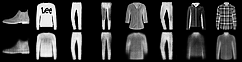

VAE_reconstructions.png


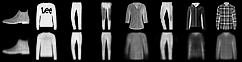

VAE_generated_samples.png


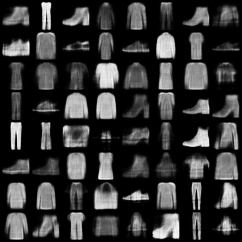

In [4]:
from IPython.display import display, Image
for filename in ["FC-AE_reconstructions.png", "VAE_reconstructions.png", "VAE_generated_samples.png"]:
    print(filename)
    display(Image(filename=filename))

Question 2 – Results and Discussion

1. I trained a Fully Connected Autoencoder (FC-AE) and a Variational Autoencoder (VAE) using the FashionMNIST dataset for 10 epochs.

2. The FC-AE achieved a test reconstruction loss of 221.992, while the VAE achieved 231.824. The VAE also had a KL divergence loss of 12.514.

3. The FC-AE performed better at reconstructing the original images based on reconstruction loss. However, the VAE has an additional advantage because it learns a smooth latent space, which allows it to generate new clothing images by sampling random latent values.

4. Both models showed decreasing training losses over the 10 epochs, indicating that they learned useful patterns from the dataset.